In [2]:
from auxillaryFunctions import *
from scipy.signal import welch

np.random.seed(0)

build_dir,configType = "build", "Release" #"Debug" Release ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={},stimInfoCurrents = {}, 
                   recordingKeys = ["voltages","calciumVals","netCurrent","current"],singleThread=False):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    ac["performanceStats"] = np.zeros(8,dtype=np.float32)


    recordingData = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)

    if singleThread:
        cathalTest.solveNeuralSystemSingleThread(ac,recordingData,TS,nIterations,samplingInterval)
    else:
        cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)
    
    #trackPerfOverTime(ac)
    recordingData["time"] = tv
    return recordingData

def getCorrectSpikerOutput(data):
    #"spikes" as recorded can last for more than one iteration because its just Vm>0 
    deriv = np.diff(data["spikerOutput"],axis=0)>0
    deriv = np.pad(deriv, ((1, 0), (0, 0)), mode='constant')
    return deriv

def getPopSpikeTrains(simData,data):
    correctOp = getCorrectSpikerOutput(data)

    spikeTimes = [[] for i in range(data["spikerOutput"].shape[1])]
    for timeInd,neurInd in zip(*np.where(correctOp)):
        spikeTimes[neurInd].append(float(data["time"][timeInd]))

    indices = {}
    for popName,popDict in  simData["indexMaps"]["neuronPopToSpikerMap"].items():
        indices[popName] = list(popDict.values())

    spikeTimeDict = {}
    for pop,inds in indices.items():
        spikeTimeDict[pop] = [spikeTimes[i] for i in inds]

    return spikeTimeDict



In [101]:
np.random.seed(0)

STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
STNbias = -2.1
GPeBias = -0.23

TS = 0.04
runTime = 3000

simScale = 30
k = 10
nSTN,nGPe = simScale,3*simScale
nCTX,nMSN = 10*simScale, 30*simScale
CTXrate,MSNrate = 3.3,2.1 #3.3,2.1
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe

#bestRes = [0.06170263, 0.03405614, 0.06633905, 0.01087161, 0.00174543]
#bestRes = [0.00704145, 0.00516796, 0.14559871, 0.00181641, 0.02500281]
bestRes = [8.90988904e-02, 6.33518893e-03, 1.67355840e+01, 2.45451547e-10, 9.75327115e-11]
wCTXToSTN =  bestRes[0] 
wSTNToGPe = bestRes[1]
wGPeToSTN = bestRes[2]
wGPeToGPe = bestRes[3]
wMSNToGPe =  bestRes[4]


parameters = {
    "simScale":simScale, "k":k,
    "nSTN":nSTN, "nGPe":nGPe,
    "nCTX":nCTX, "nMSN":nMSN,
    "CTXrate":CTXrate, "MSNrate":MSNrate,
    "nSTN_GPe":nSTN_GPe,"nGPe_GPe":nGPe_GPe,"nGPe_STN":nGPe_STN,
    "nCTX_STN":nCTX_STN,"nMSN_GPe":nMSN_GPe,
    "wSTNToGPe":wSTNToGPe, "wGPeToSTN":wGPeToSTN, "wGPeToGPe":wGPeToGPe,
    "wMSNToGPe":wMSNToGPe, "wCTXToSTN":wCTXToSTN
}


coupling,nSegments = 0.25,2 #2 segments gives 3 total segments including soma
STNDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
STNDendriteInfo = [{"channels":STNchannels,"bias":STNbias,"CaEquilibriumVal":0,
                            "CaRemovalRate":2} for _ in range(nSegments)]

GPeDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
GPeDendriteInfo = [{"channels":GPechannels,"bias":GPeBias,"CaEquilibriumVal":0,
                            "CaRemovalRate":2} for _ in range(nSegments)]

STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(nSTN)]
GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias,denderiteInfo=GPeDendriteInfo,dendriteMap=GPeDendriteMap) for i in range(nGPe)]

CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]

neuronDict = {"STN":STNNeurons,"GPe":GPeNeurons}
spikerDict = {"CTX":CTXSpikers,"MSN":MSNSpikers}


CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,wCTXToSTN,0.2,TS)
STNToGPeSynapses = createSynapses(STNNeurons,GPeNeurons,nSTN_GPe,wSTNToGPe,2,TS) #
GPeToSTNSynapses = createSynapses(GPeNeurons,STNNeurons,nGPe_STN,wGPeToSTN,4,TS)
GPeToGPeSynapses = createSynapses(GPeNeurons,GPeNeurons,nGPe_GPe,wGPeToGPe,1,TS)
MSNToGPeSynapses = createSynapses(MSNSpikers,GPeNeurons,nMSN_GPe,wMSNToGPe,0.2,TS)

synapseDict = {"CTXToSTN":CTXToSTNSynapses,"STNToGPe":STNToGPeSynapses,"GPeToSTN":GPeToSTNSynapses,
                "GPeToGPe":GPeToGPeSynapses,"MSNToGPe":MSNToGPeSynapses}


simData = genSimData(neuronDict,spikerDict,synapseDict,TS)
#print(f"Total number of channels {simData['nChannels']}")

stimInfoSpikes,stimInfoCurrents = {},{}
simDataCpp = deepcopy(simData)
simDataCpp["debugRecording"] = np.zeros_like(simDataCpp["current"])
dataCpp = solveSystemCpp(simDataCpp,TS,runTime,samplingInterval=1,stimInfoSpikes=stimInfoSpikes,
                        recordingKeys =["spikerOutput"],singleThread=False)

spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)

Elapsed time in seconds: 4.2172299


In [92]:
#TODO: fit the full segment model
#From the rasters it looks like we only have 10 GPe neurons and 30 STN, the opposite of what it should be
#Are the names being set incorrectly? is it to do with the stn dendrites?
#Current theory is that all segments are being used to generate a spike 
#I think it relates to the spikerPreNeuron variable. 
#TODO: We need to create a much simpler test system for this
#TODO: Get segments working in GPe too

STN 3.8888888888888884
GPe 35.333333333333336
CTX 3.3811111111111107
MSN 2.131851851851852


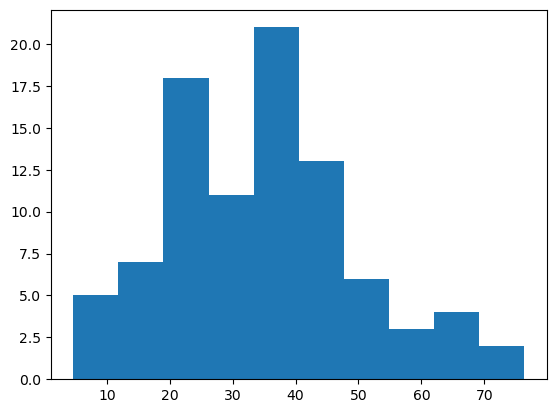

In [102]:
firingRates = {}
for pop,data in spikeTimeDict.items():
    firingRates[pop] = (1e3/runTime)* np.array([len(x) for x in data])

plt.hist(firingRates["GPe"]);
for pop,rates in firingRates.items():
    print(pop,np.mean(rates))

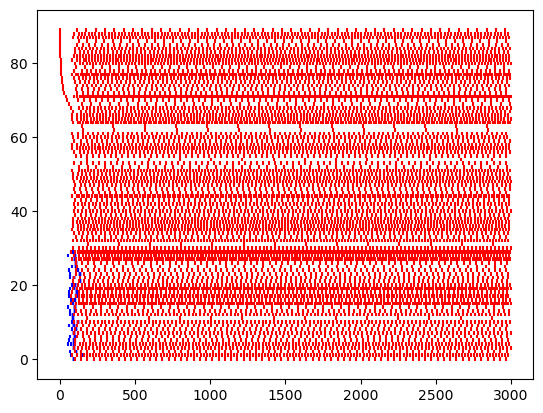

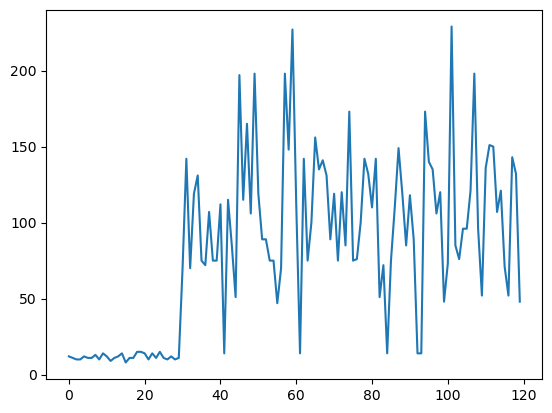

In [103]:
spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)
fig,ax = plt.subplots(1,1)
ax.eventplot(spikeTimeDict["STN"],color="b");
ax.eventplot(spikeTimeDict["GPe"],color="r");

plt.figure()
correctOp = getCorrectSpikerOutput(dataCpp)
#plt.plot(correctOp[:,0:1])
plt.plot(np.sum(correctOp,axis=0)[0:nSTN+nGPe])

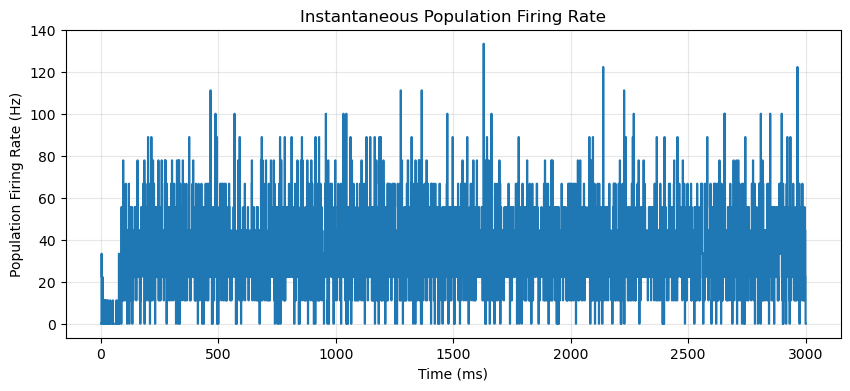

(0.0, 100.0)

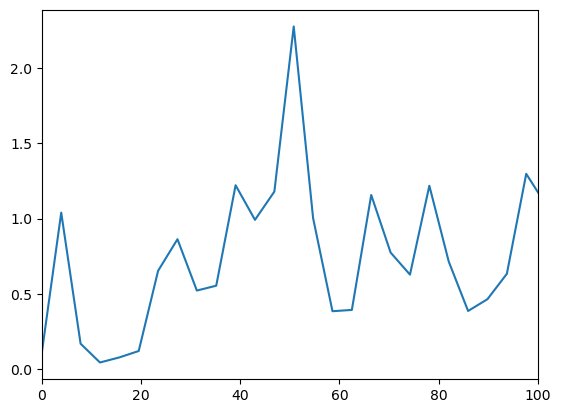

In [104]:
import numpy as np

def calculate_instantaneous_rate(spikeTimes, runTime, binsize):
    nNeurons = len(spikeTimes)
    all_spikes = np.concatenate(spikeTimes)
    bin_edges = np.arange(0, runTime + binsize, binsize)
    counts, _ = np.histogram(all_spikes, bins=bin_edges)
    rate_vector = 1e3* counts / (nNeurons * binsize)
    bin_centers = bin_edges[:-1] + (binsize / 2)

    return rate_vector, bin_centers


spikeTimes = spikeTimeDict["GPe"]

binsize = 1.0 # Using 10ms for a clearer rate plot example
# Setting runTime slightly larger than the maximum spike time to cover the full range
max_spike_time = np.max(np.concatenate(spikeTimes))
runTime = np.ceil(max_spike_time / binsize) * binsize + binsize # e.g., ~380ms

# --- Execution ---

# Calculate the rate
population_rate, time_vector = calculate_instantaneous_rate(spikeTimes, runTime, binsize)


plt.figure(figsize=(10, 4))
plt.plot(time_vector, population_rate, linestyle='-', drawstyle='steps-mid')
plt.title('Instantaneous Population Firing Rate')
plt.xlabel('Time (ms)')
plt.ylabel('Population Firing Rate (Hz)')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure()
f,pxx = welch(population_rate,fs=1000/binsize)
plt.plot(f,pxx)
plt.xlim(0,100)

In [96]:
def calcBetaLoss(popRate,binsize):
    f,pxx = welch(popRate,fs=1000/binsize)
    relativeBetaPower = np.sum(pxx[np.logical_and(13<f,f<30)])/np.sum(pxx)
    targetBetaPower = 0.1
    betaLoss = (((relativeBetaPower-targetBetaPower))/targetBetaPower)**2
    return betaLoss

binSize = 1
STNPopRate, stnTimeVec = calculate_instantaneous_rate(spikeTimeDict["STN"], runTime, binSize)
STNbetaLoss = calcBetaLoss(STNPopRate,binSize)
GPePopRate, gpeTimeVec = calculate_instantaneous_rate(spikeTimeDict["GPe"], runTime, binSize)
GPEbetaLoss = calcBetaLoss(GPePopRate,binSize)
print(STNbetaLoss,GPEbetaLoss)

0.19586621295643813 0.017717765594215968


In [83]:
def assessFiringRates(runTime = 1000,wCTXToSTN = 0.015, wSTNToGPe = 0.015,wGPeToSTN = 0.5, wGPeToGPe = 0.025, wMSNToGPe = 0.02):
    np.random.seed(0)

    STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
    GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
    STNbias = -2.1
    GPeBias = -0.23

    TS = 0.04
    # simScale = 200
    # k = 10
    # nSTN,nGPe = simScale,3*simScale
    # nCTX,nMSN = 10*simScale, 30*simScale
    # CTXrate,MSNrate = 3.3,2.1 #3.3,2.1
    # nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe

    
    simScale = 30
    k = 10
    nSTN,nGPe = simScale,3*simScale
    nCTX,nMSN = 10*simScale, 30*simScale
    CTXrate,MSNrate = 3.3,2.1 #3.3,2.1
    nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe

    parameters = {
        "simScale":simScale, "k":k,
        "nSTN":nSTN, "nGPe":nGPe,
        "nCTX":nCTX, "nMSN":nMSN,
        "CTXrate":CTXrate, "MSNrate":MSNrate,
        "nSTN_GPe":nSTN_GPe,"nGPe_GPe":nGPe_GPe,"nGPe_STN":nGPe_STN,
        "nCTX_STN":nCTX_STN,"nMSN_GPe":nMSN_GPe,
        "wSTNToGPe":wSTNToGPe, "wGPeToSTN":wGPeToSTN, "wGPeToGPe":wGPeToGPe,
        "wMSNToGPe":wMSNToGPe, "wCTXToSTN":wCTXToSTN
    }

    coupling,nSegments = 0.25,2 #2 segments gives 3 total segments including soma
    STNDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
    STNDendriteInfo = [{"channels":STNchannels,"bias":STNbias,"CaEquilibriumVal":0,
                                "CaRemovalRate":2} for _ in range(nSegments)]

    GPeDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
    GPeDendriteInfo = [{"channels":GPechannels,"bias":GPeBias,"CaEquilibriumVal":0,
                                "CaRemovalRate":2} for _ in range(nSegments)]

    STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(nSTN)]
    GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias,denderiteInfo=GPeDendriteInfo,dendriteMap=GPeDendriteMap) for i in range(nGPe)]


    CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
    MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]

    neuronDict = {"STN":STNNeurons,"GPe":GPeNeurons}
    spikerDict = {"CTX":CTXSpikers,"MSN":MSNSpikers}


    CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,wCTXToSTN,0.2,TS)
    STNToGPeSynapses = createSynapses(STNNeurons,GPeNeurons,nSTN_GPe,wSTNToGPe,2,TS) #
    GPeToSTNSynapses = createSynapses(GPeNeurons,STNNeurons,nGPe_STN,wGPeToSTN,4,TS)
    GPeToGPeSynapses = createSynapses(GPeNeurons,GPeNeurons,nGPe_GPe,wGPeToGPe,1,TS)
    MSNToGPeSynapses = createSynapses(MSNSpikers,GPeNeurons,nMSN_GPe,wMSNToGPe,0.2,TS)

    synapseDict = {"CTXToSTN":CTXToSTNSynapses,"STNToGPe":STNToGPeSynapses,"GPeToSTN":GPeToSTNSynapses,
                    "GPeToGPe":GPeToGPeSynapses,"MSNToGPe":MSNToGPeSynapses}


    simData = genSimData(neuronDict,spikerDict,synapseDict,TS)
    #print(f"Total number of channels {simData['nChannels']}")

    stimInfoSpikes,stimInfoCurrents = {},{}
    simDataCpp = deepcopy(simData)
    simDataCpp["debugRecording"] = np.zeros_like(simDataCpp["current"])
    dataCpp = solveSystemCpp(simDataCpp,TS,runTime,samplingInterval=1,stimInfoSpikes=stimInfoSpikes,
                            recordingKeys =["spikerOutput"],singleThread=False)
    
    spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)
    firingRates = {}
    for pop,data in spikeTimeDict.items():
        firingRates[pop] = (1e3/runTime)* sum([len(x) for x in data])/len(data)

    binSize = 1
    STNPopRate, stnTimeVec = calculate_instantaneous_rate(spikeTimeDict["STN"], runTime, binSize)
    STNbetaLoss = calcBetaLoss(STNPopRate,binSize)
    GPePopRate, gpeTimeVec = calculate_instantaneous_rate(spikeTimeDict["GPe"], runTime, binSize)
    GPebetaLoss = calcBetaLoss(GPePopRate,binSize)

    derivedData = {}
    derivedData["firingRates"] = firingRates
    derivedData["STNBetaLoss"] = STNbetaLoss
    derivedData["GPeBetaLoss"] = GPebetaLoss
    derivedData["parameters"] = parameters

    return derivedData


ipVector = [0.015, 0.015, 0.5, 0.025, 0.02]
def calcLoss(ipVector):
    data = assessFiringRates(runTime=1000, wCTXToSTN=ipVector[0], wSTNToGPe=ipVector[1],
                            wGPeToSTN=ipVector[2], wGPeToGPe=ipVector[3], wMSNToGPe=ipVector[4])
    targetSTN = 10
    targetGPe = 30
    loss = (((data["firingRates"]["STN"]-targetSTN))/targetSTN )**2
    loss += (((data["firingRates"]["GPe"]-targetGPe))/targetGPe )**2

    loss += data["STNBetaLoss"]
    loss += data["GPeBetaLoss"]
    return loss

# from scipy.optimize import minimize
# maxIter = 50
# res = minimize(calcLoss, ipVector, method='Nelder-Mead', options={'xatol': 1e-4, 'disp': True,"maxiter":maxIter})

bestRes = [0.01705435, 0.10641351, 0.00225679, 0.00061382, 0.15976327]
calcLoss(bestRes)

Elapsed time in seconds: 1.4282542


np.float64(2.7084272207373195)

In [98]:
def calcLoss(logParams, nTrials=1):
    runTime = 1200
    targetSTN = 10.0
    targetGPe = 30.0

    params = np.exp(logParams)

    losses = []
    for _ in range(nTrials):
        data = assessFiringRates(
            runTime=runTime,
            wCTXToSTN=params[0],
            wSTNToGPe=params[1],
            wGPeToSTN=params[2],
            wGPeToGPe=params[3],
            wMSNToGPe=params[4],
        )

        loss = (((data["firingRates"]["STN"]-targetSTN))/targetSTN )**2
        loss +=  (((data["firingRates"]["GPe"]-targetGPe))/targetGPe )**2
        #weighting the betapower loss as less than the firing rates
        loss += 0.25*data["STNBetaLoss"]
        loss += 0.25*data["GPeBetaLoss"]

        losses.append(loss)

    return float(np.mean(losses))

import cma

# initial guess (log space)
x0 = np.log([0.015, 0.015, 0.5, 0.025, 0.02])

# global step size (log-space)
sigma0 = 0.5

es = cma.CMAEvolutionStrategy(
    x0,
    sigma0,
    {
        "popsize": 40,
        "maxiter": 20,
        "verb_disp": 1,
    }
)

(20_w,40)-aCMA-ES (mu_w=11.3,w_1=16%) in dimension 5 (seed=261376, Wed Dec 31 12:19:48 2025)


In [99]:
import time
t0 = time.time()
allLosses = []
while not es.stop():
    solutions = es.ask()
    losses = [calcLoss(x) for x in solutions]
    allLosses.append(losses)
    print(losses)
    print(f"Best loss {min(losses)}")
    es.tell(solutions, losses)
t1 = time.time()
bestLogParams = es.result.xbest
bestParams = np.exp(bestLogParams)


print("Best parameters:", bestParams)
print("Best loss:", es.result.fbest)

print(f"Total time taken {t1-t0:.2f}")

Elapsed time in seconds: 1.6432802000000002
Elapsed time in seconds: 1.6831191
Elapsed time in seconds: 1.6543005000000002
Elapsed time in seconds: 1.7126890000000001
Elapsed time in seconds: 1.6682151
Elapsed time in seconds: 1.7016712
Elapsed time in seconds: 1.6805859
Elapsed time in seconds: 1.7242154
Elapsed time in seconds: 1.6932823000000001
Elapsed time in seconds: 1.7285807000000002
Elapsed time in seconds: 1.6937093
Elapsed time in seconds: 1.7316978
Elapsed time in seconds: 1.7144927
Elapsed time in seconds: 1.7461713
Elapsed time in seconds: 1.6946574
Elapsed time in seconds: 1.7100349000000001
Elapsed time in seconds: 1.7079162
Elapsed time in seconds: 1.7245112
Elapsed time in seconds: 1.7237641000000001
Elapsed time in seconds: 1.7116523000000001
Elapsed time in seconds: 1.7558428000000001
Elapsed time in seconds: 1.7226224
Elapsed time in seconds: 1.7696898
Elapsed time in seconds: 1.7464687
Elapsed time in seconds: 1.7628052
Elapsed time in seconds: 1.7336961000000002


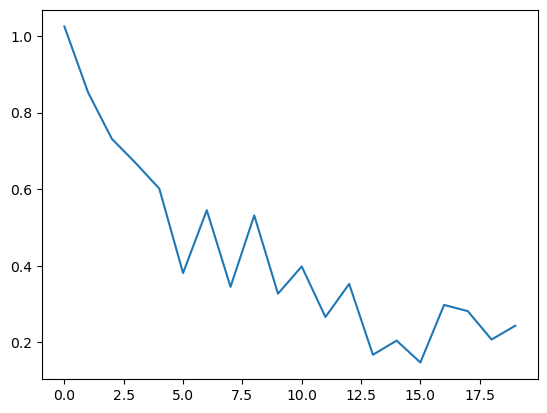

In [100]:
minLoss = [min(x) for x in allLosses]
plt.plot(minLoss)

In [47]:
0.017, 0.1064, 0.00225, 0.00006, 0.15


array([14.88723148, 16.89334954, 17.50058333, 17.63006481, 17.6927037 ,
       17.71514583])

In [3]:
STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()
STNbias = -2.1
GPeBias = -0.23

TS = 0.04
simScale = 10
k = 10
nSTN,nGPe,nIdk = simScale,3*simScale,0
nCTX,nMSN = 10*simScale, 30*simScale
CTXrate,MSNrate = 3.3,2.1 #3.3,2.1
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe


coupling,nSegments = 0.25,2 #2 segments gives 3 total segments including soma
STNDendriteMap = [(i+1,0,coupling) for i in range(nSegments)]
STNDendriteInfo = [{"channels":STNchannels,"bias":STNbias,"CaEquilibriumVal":0,
                            "CaRemovalRate":2} for _ in range(nSegments)]

STNNeurons = [Neuron(i,"STN","excitatory",AISchannels=STNchannels,AISbias=STNbias,denderiteInfo=STNDendriteInfo,dendriteMap=STNDendriteMap) for i in range(nSTN)]
GPeNeurons = [Neuron(i,"GPe","inhibitory",AISchannels=GPechannels,AISbias=GPeBias) for i in range(nGPe)]

CTXSpikers = [Spiker(i,"CTX","excitatory",CTXrate,TS) for i in range(nCTX)]
MSNSpikers = [Spiker(i,"MSN","inhibitory",MSNrate,TS) for i in range(nMSN)]

neuronDict = {"STN":STNNeurons,"GPe":GPeNeurons}
spikerDict = {"CTX":CTXSpikers,"MSN":MSNSpikers}

CTXToSTNSynapses = createSynapses(CTXSpikers,STNNeurons,nCTX_STN,0.015,0.2,TS)
STNToGPeSynapses = createSynapses(STNNeurons,GPeNeurons,nSTN_GPe,0.015,4,TS) #
GPeToSTNSynapses = createSynapses(GPeNeurons,STNNeurons,nGPe_STN,0.5,4,TS)
GPeToGPeSynapses = createSynapses(GPeNeurons,GPeNeurons,nGPe_GPe,0.025,4,TS)
MSNToGPeSynapses = createSynapses(MSNSpikers,GPeNeurons,nGPe_GPe,0.02,0.2,TS)

synapseDict = {"CTXToSTN":CTXToSTNSynapses,"STNToGPe":STNToGPeSynapses,"GPeToSTN":GPeToSTNSynapses,
                "GPeToGPe":GPeToGPeSynapses,"MSNToGPe":MSNToGPeSynapses}


simData = genSimData(neuronDict,spikerDict,synapseDict,TS)
print(f"Total number of channels {simData['nChannels']}")

    



runTime = 1000
stimInfoSpikes,stimInfoCurrents = {},{}
simDataCpp = deepcopy(simData)
simDataCpp["debugRecording"] = np.zeros_like(simDataCpp["current"])
dataCpp = solveSystemCpp(simDataCpp,TS,runTime,samplingInterval=4,stimInfoSpikes=stimInfoSpikes,
                         recordingKeys =["voltages","calciumVals","netCurrent","x","debugRecording","CaChannelCurrent","spikerOutput"])



Elapsed time in seconds: 1.0574165


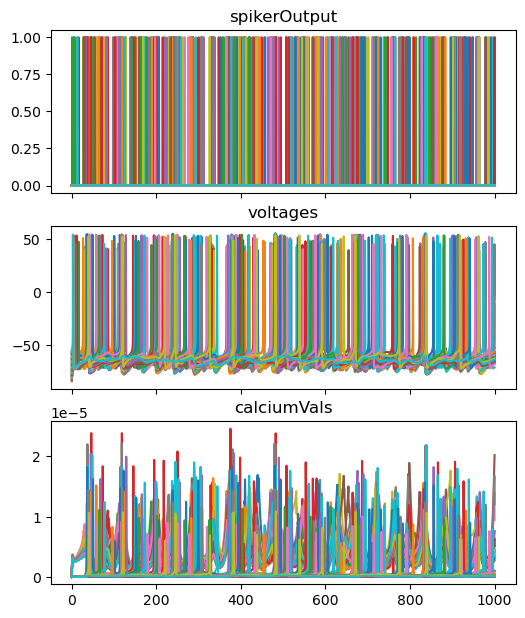

In [4]:
keysToPlot = ["spikerOutput","voltages","calciumVals","time"]
standardPlot({key:dataCpp[key] for key in keysToPlot})

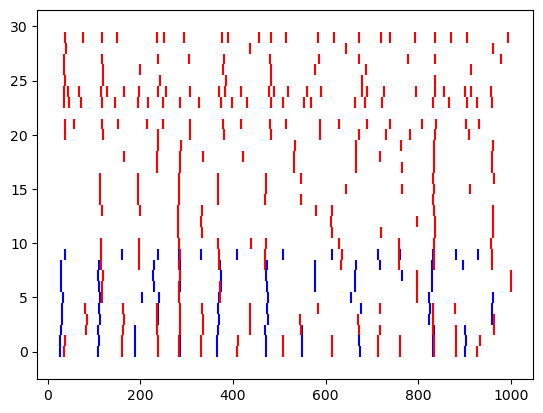

In [5]:


spikeTimeDict = getPopSpikeTrains(simDataCpp,dataCpp)
fig,ax = plt.subplots(1,1)
ax.eventplot(spikeTimeDict["STN"],color="b");
ax.eventplot(spikeTimeDict["GPe"],color="r");

: 

In [20]:
frs

{'STN': 6.72, 'GPe': 7.56, 'CTX': 3.28, 'MSN': 2.119666666666667}

In [ ]:
#TODO: Dec 1st 2025. 
#Next is to get firing rates, and instantaneuos firing rate plots
#Then update the CPP code
#Then tune the STN-GPe net

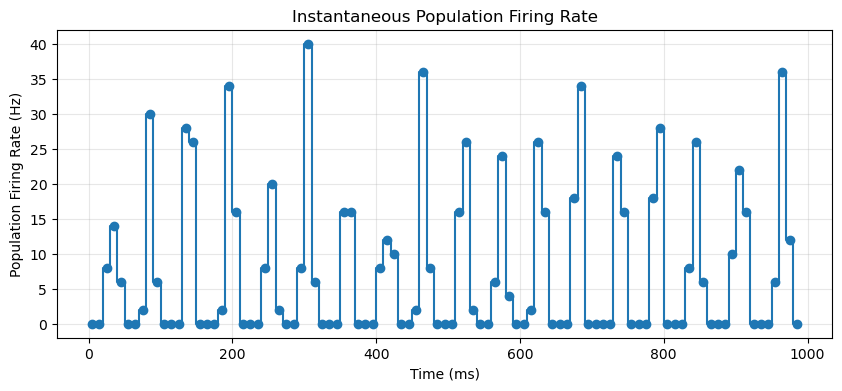

In [ ]:
stimInfoSpikes = {}
syns = [i for i,n in enumerate(simData["name"]) if n == "AMPAR"] #"AMPAR" #GABA
#stimSynapse(stimInfoSpikes,syns,50,100,TS

runTime = 400
stimInfoCurrents = {} 

simDataPy = deepcopy(simData)
simDataPy["debugRecording"] = np.zeros_like(simDataPy["current"])

data = solveSystemStandard(simDataPy,TS,runTime,stimInfoSpikes,stimInfoCurrents,vectorized=True,nSamples=None, useTQDM=True,
                           recordingKeys = ["voltages","calciumVals","netCurrent","x","debugRecording","CaChannelCurrent","spikerOutput"])

#TODO: add spike recording to cpp side
simDataPy["spikeTrains"]; #NOTE: I dont like this philosophy of this and it sholud be removed later. Keep state and recording data separate 


In [2]:
build_dir,configType = "build", "Release" #"Debug" Release ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

    
def solveSystemCpp(ac,TS,runTime,samplingInterval=2,stimInfoSpikes={},stimInfoCurrents = {}, recordingKeys = ["voltages","calciumVals","netCurrent","current"]):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    spikeStimTimes,spikeStimNeurons = genSpikeStimArrays(stimInfoSpikes)
    ac["spikeStimTimes"] = spikeStimTimes
    ac["spikeStimNeurons"] = spikeStimNeurons

    biasStimTimes,biasStimSegments,biasStimValues = genBiasStimArrays(stimInfoCurrents)
    ac["biasStimTimes"] = biasStimTimes
    ac["biasStimSegments"] = biasStimSegments
    ac["biasStimValues"] = biasStimValues
    ac["performanceStats"] = np.zeros(8,dtype=np.float32)


    recordingData = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        recordingData[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)
    print("here")
    cathalTest.solveNeuralSystem(ac,recordingData,TS,nIterations,samplingInterval)

    #trackPerfOverTime(ac)

    recordingData["time"] = tv
    return recordingData



stimInfoSpikes,stimInfoCurrents = {},{}
allChannelDataCpp = deepcopy(simData)
allChannelDataCpp["debugRecording"] = np.zeros_like(simDataPy["current"])
dataCpp = solveSystemCpp(allChannelDataCpp,TS,runTime,samplingInterval=4,stimInfoSpikes=stimInfoSpikes,
                         recordingKeys = ["voltages","calciumVals","current"])



NameError: name 'simDataPy' is not defined